(sec-10-2)=
# 10.2 The Wiener Filter

Record an ECG on a patient who is shivering, or on a runner at the peak of a treadmill stress test, and the trace fills with a fine, irregular hash. This is electrical activity from the chest and limb muscles, and unlike power-line hum it does not sit at one frequency. Its spectrum stretches from a few hertz to well above 100 Hz and covers the band where the QRS complex keeps most of its energy. Any fixed filter is therefore a compromise. A low cutoff removes more noise but rounds the QRS and lowers the R peak; a high cutoff keeps the QRS sharp but lets most of the noise through. Where exactly should the compromise lie?

Norbert Wiener answered this question in the 1940s for a precise version of the problem {cite:p}`wiener1949`. If we know the second-order statistics of the signal and the noise (their autocorrelations, or equivalently their power spectra), there is a single linear filter that minimizes the mean squared error between its output and the true signal, and it can be computed in closed form. In the frequency domain the answer is remarkably simple: at each frequency the filter applies a gain equal to the fraction of the observed power that belongs to the signal. Where the signal dominates the gain is close to one, where the noise dominates it is close to zero, and in between it slides smoothly.

I derive the Wiener filter twice: first as a finite impulse response (FIR) filter, through the orthogonality principle and the Wiener–Hopf equations, and then as a non-causal filter in the frequency domain. We then apply both to an MIT-BIH ECG corrupted by real muscle noise from the Noise Stress Test Database, estimate the signal spectrum from averaged beats as in [Section 10.1](01_signal_averaging.ipynb), and compare the results with fixed low-pass filters. The comparison teaches two things. The Wiener filter beats every fixed low-pass, and it also tells us how much any linear time-invariant filter can possibly achieve, which turns out to be less than one might hope.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal, linalg

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-10-2-1)=
## 10.2.1 The Linear Estimation Problem

We observe a noisy recording

$$
x[n] = s[n] + v[n],
$$

where $s[n]$ is the signal we care about and $v[n]$ is additive noise. Both are modeled as zero-mean, wide-sense stationary random processes ([Section 7.1](../ch12_spectral_estimation/01_random_processes.ipynb)), and we assume that the signal and the noise are uncorrelated, $\mathbb{E}\big[s[n]\,v[m]\big] = 0$ for all $n, m$. For muscle noise on an ECG this is physically reasonable: the electrical activity of skeletal muscle has nothing to do with the timing or shape of the cardiac cycle.

We look for an FIR filter with $M$ coefficients $w_0, \ldots, w_{M-1}$ whose output

$$
\hat{s}[n] = \sum_{k=0}^{M-1} w_k\, x[n-k] = \mathbf{w}^\mathsf{T}\mathbf{x}[n],
\qquad
\mathbf{x}[n] = \begin{bmatrix} x[n] & x[n-1] & \cdots & x[n-M+1] \end{bmatrix}^\mathsf{T},
$$

is as close as possible to a **desired signal** $d[n]$. Usually $d[n] = s[n]$. Offline, we can do better by asking for a slightly delayed version, $d[n] = s[n-D]$, so that the filter sees $D$ samples of "future" input around the sample it estimates. This is called *smoothing*, and we will see that it matters a great deal for a waveform as sharp as the QRS complex.

"As close as possible" needs a definition. We use the **mean squared error** (MSE),

(eq-10-10)=
\begin{equation*}
J(\mathbf{w}) = \mathbb{E}\big[e^2[n]\big], \qquad e[n] = d[n] - \mathbf{w}^\mathsf{T}\mathbf{x}[n]. \tag{10.10}
\end{equation*}

The MSE is not the only sensible criterion, but it has two great advantages: it depends only on second-order statistics, and, as we now show, it is a quadratic function of the coefficients with a single minimum.

**Expanding the cost.** Squaring the error and taking expectations term by term,

(eq-10-11)=
\begin{equation*}
\begin{aligned}
J(\mathbf{w}) &= \mathbb{E}\big[(d[n] - \mathbf{w}^\mathsf{T}\mathbf{x}[n])^2\big] \\
&= \mathbb{E}\big[d^2[n]\big] - 2\,\mathbf{w}^\mathsf{T}\,\mathbb{E}\big[d[n]\,\mathbf{x}[n]\big] + \mathbf{w}^\mathsf{T}\,\mathbb{E}\big[\mathbf{x}[n]\,\mathbf{x}^\mathsf{T}[n]\big]\,\mathbf{w} \\
&= \sigma_d^2 - 2\,\mathbf{w}^\mathsf{T}\mathbf{p} + \mathbf{w}^\mathsf{T}\mathbf{R}\,\mathbf{w}.
\end{aligned} \tag{10.11}
\end{equation*}

In the second line we used two facts: $\mathbf{w}$ is a constant and can be pulled out of the expectation, and $\mathbf{w}^\mathsf{T}\mathbf{x}$ is a scalar, so $(\mathbf{w}^\mathsf{T}\mathbf{x})^2 = \mathbf{w}^\mathsf{T}\mathbf{x}\,\mathbf{x}^\mathsf{T}\mathbf{w}$. Two statistical objects appear:

- The **input autocorrelation matrix** $\mathbf{R} = \mathbb{E}\big[\mathbf{x}[n]\mathbf{x}^\mathsf{T}[n]\big]$, whose $(i, k)$ entry is $\mathbb{E}\big[x[n-i]\,x[n-k]\big] = R_x[k-i]$. Because the process is stationary, the entry depends only on the lag $k - i$, so $\mathbf{R}$ is symmetric and constant along each diagonal (a *Toeplitz* matrix).
- The **cross-correlation vector** $\mathbf{p} = \mathbb{E}\big[d[n]\,\mathbf{x}[n]\big]$, with entries $p_k = \mathbb{E}\big[d[n]\,x[n-k]\big]$, which measures how strongly each input sample is related to the target.

(sec-10-2-2)=
## 10.2.2 The Orthogonality Principle and the Wiener–Hopf Equations

### Setting the gradient to zero

$J(\mathbf{w})$ is a quadratic bowl in $M$ dimensions, and at its minimum all partial derivatives vanish. We differentiate [(10.10)](#eq-10-10) with respect to one coefficient $w_k$. The derivative can be moved inside the expectation, the chain rule turns $\partial e^2/\partial w_k$ into $2e\,\partial e/\partial w_k$, and $\partial e[n]/\partial w_k = -x[n-k]$ because $w_k$ multiplies $x[n-k]$ in the estimate. Hence

$$
\frac{\partial J}{\partial w_k} = \mathbb{E}\!\left[2\,e[n]\,\frac{\partial e[n]}{\partial w_k}\right] = -2\,\mathbb{E}\big[e[n]\,x[n-k]\big].
$$

Setting this to zero for every $k$ gives the **orthogonality principle**: the filter is optimal exactly when

(eq-10-12)=
\begin{equation*}
\mathbb{E}\big[e_o[n]\,x[n-k]\big] = 0, \qquad k = 0, 1, \ldots, M-1, \tag{10.12}
\end{equation*}

where $e_o[n]$ is the error of the optimal filter. In words, the optimal error is uncorrelated with every input sample the filter uses. The geometric picture behind the name is the one from [Section 2.2](../ch02_math_toolkit/03_signals_as_vectors.ipynb). If we treat zero-mean random variables as vectors with inner product $\langle a, b\rangle = \mathbb{E}[ab]$, the estimate $\hat{s}[n]$ is a vector in the subspace spanned by the input samples, and the best estimate is the orthogonal projection of $d[n]$ onto that subspace. What is left over, the error, is perpendicular to the subspace. If it were not, some combination of the inputs would still "explain" part of the error and could be added to the estimate to reduce it.

### From orthogonality to a linear system

We substitute $e_o[n] = d[n] - \sum_i w_i\, x[n-i]$ into [(10.12)](#eq-10-12), move the sum out of the expectation (the $w_i$ are constants), and recognize the correlations:

$$
\begin{aligned}
\mathbb{E}\Big[\Big(d[n] - \sum_{i=0}^{M-1} w_i\,x[n-i]\Big)\,x[n-k]\Big] &= 0 \\
\sum_{i=0}^{M-1} w_i\,\mathbb{E}\big[x[n-i]\,x[n-k]\big] &= \mathbb{E}\big[d[n]\,x[n-k]\big] \\
\sum_{i=0}^{M-1} w_i\,R_x[k-i] &= p_k, \qquad k = 0, \ldots, M-1.
\end{aligned}
$$

These $M$ equations in $M$ unknowns are the **Wiener–Hopf equations**. In matrix form,

(eq-10-13)=
\begin{equation*}
\begin{bmatrix}
R_x[0] & R_x[1] & \cdots & R_x[M-1] \\
R_x[1] & R_x[0] & \cdots & R_x[M-2] \\
\vdots & \vdots & \ddots & \vdots \\
R_x[M-1] & R_x[M-2] & \cdots & R_x[0]
\end{bmatrix}
\begin{bmatrix} w_0 \\ w_1 \\ \vdots \\ w_{M-1}\end{bmatrix}
=
\begin{bmatrix} p_0 \\ p_1 \\ \vdots \\ p_{M-1}\end{bmatrix},
\qquad\text{i.e.}\qquad
\mathbf{R}\,\mathbf{w}_o = \mathbf{p}. \tag{10.13}
\end{equation*}

We used $R_x[-m] = R_x[m]$, true for any real stationary process. The same result follows from differentiating the matrix form [(10.11)](#eq-10-11) directly: the gradient of $\mathbf{w}^\mathsf{T}\mathbf{p}$ is $\mathbf{p}$, the gradient of $\mathbf{w}^\mathsf{T}\mathbf{R}\mathbf{w}$ is $2\mathbf{R}\mathbf{w}$ for symmetric $\mathbf{R}$, and so $\nabla J = -2\mathbf{p} + 2\mathbf{R}\mathbf{w}$, which vanishes when $\mathbf{R}\mathbf{w} = \mathbf{p}$. I find it reassuring that the two routes, one through geometry and one through calculus, land on the same equation.

### The minimum error and the shape of the bowl

Substituting $\mathbf{w}_o$ into [(10.11)](#eq-10-11) and using $\mathbf{R}\mathbf{w}_o = \mathbf{p}$ to replace $\mathbf{w}_o^\mathsf{T}\mathbf{R}\mathbf{w}_o$ by $\mathbf{w}_o^\mathsf{T}\mathbf{p}$,

(eq-10-14)=
\begin{equation*}
J_{\min} = \sigma_d^2 - 2\,\mathbf{w}_o^\mathsf{T}\mathbf{p} + \mathbf{w}_o^\mathsf{T}\mathbf{p} = \sigma_d^2 - \mathbf{p}^\mathsf{T}\mathbf{w}_o. \tag{10.14}
\end{equation*}

For any other coefficient vector the cost is larger by a quadratic term. Expanding $(\mathbf{w} - \mathbf{w}_o)^\mathsf{T}\mathbf{R}(\mathbf{w} - \mathbf{w}_o) = \mathbf{w}^\mathsf{T}\mathbf{R}\mathbf{w} - 2\mathbf{w}^\mathsf{T}\mathbf{p} + \mathbf{w}_o^\mathsf{T}\mathbf{p}$ (again using $\mathbf{R}\mathbf{w}_o = \mathbf{p}$ and the symmetry of $\mathbf{R}$) and adding $J_{\min}$ recovers [(10.11)](#eq-10-11), so

(eq-10-15)=
\begin{equation*}
J(\mathbf{w}) = J_{\min} + (\mathbf{w} - \mathbf{w}_o)^\mathsf{T}\,\mathbf{R}\,(\mathbf{w} - \mathbf{w}_o). \tag{10.15}
\end{equation*}

Because $\mathbf{R}$ is positive definite for any process that is not perfectly predictable, the second term is positive for every $\mathbf{w} \ne \mathbf{w}_o$, and the minimum is unique. The contours of $J$ are ellipses centered on $\mathbf{w}_o$ whose axes point along the eigenvectors of $\mathbf{R}$. This geometry returns in Section 16.3, where adaptive filters walk down the bowl one step at a time.

### Signal plus uncorrelated noise

For our model $x = s + v$ with $d[n] = s[n-D]$, the cross terms between signal and noise vanish in every expectation:

$$
\begin{aligned}
R_x[m] &= \mathbb{E}\big[(s[n] + v[n])(s[n+m] + v[n+m])\big] = R_s[m] + R_v[m], \\
p_k &= \mathbb{E}\big[s[n-D]\,(s[n-k] + v[n-k])\big] = R_s[k-D].
\end{aligned}
$$

So the filter needs the autocorrelation of the signal, the autocorrelation of the noise, and nothing else.

**Example 10.2.1.** Let the signal be a first-order autoregressive process with unit variance, $R_s[m] = a^{|m|}$ with $a = 0.9$, and let the noise be white with variance $\sigma_v^2 = 1$, so $R_v[m] = \delta[m]$ and the input SNR is 0 dB. Find the optimal two-tap causal filter ($M = 2$, $D = 0$) and its MSE.

The needed correlations are $R_x[0] = 1 + 1 = 2$, $R_x[1] = 0.9$, $p_0 = R_s[0] = 1$ and $p_1 = R_s[1] = 0.9$. The Wiener–Hopf equations read

$$
\begin{bmatrix} 2 & 0.9 \\ 0.9 & 2 \end{bmatrix}
\begin{bmatrix} w_0 \\ w_1 \end{bmatrix}
= \begin{bmatrix} 1 \\ 0.9 \end{bmatrix}.
$$

The determinant is $2\cdot 2 - 0.9^2 = 3.19$. Inverting the $2\times 2$ matrix by swapping the diagonal entries, negating the off-diagonal ones and dividing by the determinant,

$$
\begin{bmatrix} w_0 \\ w_1 \end{bmatrix}
= \frac{1}{3.19}\begin{bmatrix} 2 & -0.9 \\ -0.9 & 2 \end{bmatrix}\begin{bmatrix} 1 \\ 0.9 \end{bmatrix}
= \frac{1}{3.19}\begin{bmatrix} 2 - 0.81 \\ -0.9 + 1.8 \end{bmatrix}
= \begin{bmatrix} 0.3730 \\ 0.2821 \end{bmatrix}.
$$

From [(10.14)](#eq-10-14), $J_{\min} = 1 - (1 \cdot 0.3730 + 0.9 \cdot 0.2821) = 1 - 0.6270 = 0.3730$. Doing nothing ($\hat{s} = x$) leaves an MSE of $\sigma_v^2 = 1$, so the two-tap filter reduces the error power by $10\log_{10}(1/0.373) = 4.28$ dB. Look at what the filter does: it averages the current and previous samples with weights that sum to about 0.65. The averaging suppresses the white noise, which is uncorrelated from sample to sample, while the strongly correlated AR(1) signal survives it. The overall scaling below one shrinks the estimate towards zero, which is the right thing to do when half of the observed power is noise.

We verify the hand calculation and then check the orthogonality principle on a long simulated realization, estimating the correlations from data exactly as we will do with the ECG.

In [2]:
a, var_v = 0.9, 1.0
R = np.array([[1 + var_v, a], [a, 1 + var_v]])
p = np.array([1.0, a])
w_o = np.linalg.solve(R, p)
J_min = 1.0 - p @ w_o
print(f"Wiener coefficients     : w0 = {w_o[0]:.4f}, w1 = {w_o[1]:.4f}")
print(f"Minimum MSE (16.14)     : {J_min:.4f}   (no filtering: {var_v:.4f})")
print(f"Error power reduction   : {10 * np.log10(var_v / J_min):.2f} dB")

Wiener coefficients     : w0 = 0.3730, w1 = 0.2821
Minimum MSE (16.14)     : 0.3730   (no filtering: 1.0000)
Error power reduction   : 4.28 dB


In [3]:
n_sim = 200_000
u = rng.normal(0, np.sqrt(1 - a**2), n_sim)          # driving noise for a unit-variance AR(1)
s_ar = signal.lfilter([1.0], [1.0, -a], u)
x_ar = s_ar + rng.normal(0, np.sqrt(var_v), n_sim)


def corr_est(y, z, max_lag):
    """Biased estimate of E[y[n] z[n-k]] for k = 0..max_lag-1."""
    N = len(y)
    return np.array([np.dot(y[k:], z[:N - k]) / N for k in range(max_lag)])


r_hat = corr_est(x_ar, x_ar, 2)
p_hat = corr_est(s_ar, x_ar, 2)
w_hat = np.linalg.solve(linalg.toeplitz(r_hat), p_hat)
e_opt = s_ar - signal.lfilter(w_hat, [1.0], x_ar)
e_avg = s_ar - signal.lfilter([0.5, 0.5], [1.0], x_ar)
print(f"Coefficients from data   : w0 = {w_hat[0]:.4f}, w1 = {w_hat[1]:.4f}")
print(f"E[e x[n-k]], optimal     : {corr_est(e_opt, x_ar, 2)}")
print(f"E[e x[n-k]], w = [.5, .5]: {corr_est(e_avg, x_ar, 2)}")
print(f"MSE optimal / [.5, .5]   : {np.mean(e_opt**2):.4f} / {np.mean(e_avg**2):.4f}")

Coefficients from data   : w0 = 0.3732, w1 = 0.2823
E[e x[n-k]], optimal     : [0. 0.]
E[e x[n-k]], w = [.5, .5]: [-0.4499 -0.5491]
MSE optimal / [.5, .5]   : 0.3740 / 0.5506


The coefficients estimated from 200,000 samples agree with the hand calculation to three decimals, and the error of the optimal filter is uncorrelated with both input samples, while the plain two-point average leaves a clearly nonzero correlation and a larger MSE. The error surface of this example is drawn below. The elliptical contours are the level sets of [(10.15)](#eq-10-15), and both "do nothing" ($\mathbf{w} = [1, 0]$) and "output zero" ($\mathbf{w} = [0, 0]$) lie on the contour $J = 1$.

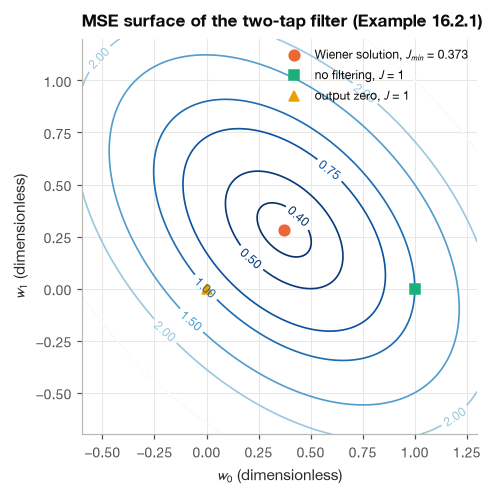

In [4]:
w0_grid, w1_grid = np.meshgrid(np.linspace(-0.6, 1.3, 300), np.linspace(-0.7, 1.2, 300))
dW = np.stack([w0_grid - w_o[0], w1_grid - w_o[1]])
J_grid = J_min + np.einsum("i...,ij,j...->...", dW, R, dW)   # equation (16.15)

fig, ax = plt.subplots(figsize=(5.2, 4.4))
cs = ax.contour(w0_grid, w1_grid, J_grid, levels=[0.4, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0],
                cmap="Blues_r", linewidths=1.1)
ax.clabel(cs, fontsize=8, fmt="%.2f")
ax.plot(*w_o, "o", color=C[1], ms=7, label=f"Wiener solution, $J_{{min}}$ = {J_min:.3f}")
ax.plot(1, 0, "s", color=C[2], ms=6, label="no filtering, $J$ = 1")
ax.plot(0, 0, "^", color=C[3], ms=6, label="output zero, $J$ = 1")
ax.set(xlabel="$w_0$ (dimensionless)", ylabel="$w_1$ (dimensionless)",
       title="MSE surface of the two-tap filter (Example 16.2.1)")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=8)
plt.show()

(sec-10-2-3)=
## 10.2.3 The Non-Causal Wiener Filter in the Frequency Domain

The FIR solution is practical, but it hides the structure of the answer inside a matrix inverse. To see that structure, we remove all restrictions on the filter: let it have infinitely many coefficients $h[k]$, on both sides of $k = 0$, and estimate $s[n]$ from the entire record. This non-causal filter can only be applied offline, but it is the best any linear time-invariant filter can do, and its form is easy to interpret.

**Step 1: write the orthogonality conditions for all lags.** With $\hat{s}[n] = \sum_{i=-\infty}^{\infty} h[i]\,x[n-i]$, the derivation that led to [(10.13)](#eq-10-13) goes through unchanged, except that $k$ now ranges over all integers:

(eq-10-16)=
\begin{equation*}
\sum_{i=-\infty}^{\infty} h[i]\,R_x[k-i] = R_{sx}[k], \qquad -\infty < k < \infty, \tag{10.16}
\end{equation*}

where $R_{sx}[k] = \mathbb{E}\big[s[n]\,x[n-k]\big]$.

**Step 2: recognize a convolution.** The left-hand side is the convolution $(h * R_x)[k]$, evaluated at every $k$. A finite matrix system has become a convolution identity between two sequences.

**Step 3: take the DTFT of both sides.** Convolution becomes multiplication, and by the Wiener–Khinchin theorem ([Section 7.2](../ch12_spectral_estimation/02_power_spectral_density.ipynb)) the DTFT of an autocorrelation is a power spectral density. Writing $S_x(\Omega)$ for the PSD of $x$ and $S_{sx}(\Omega)$ for the cross-spectrum,

(eq-10-17)=
\begin{equation*}
H(e^{j\Omega})\,S_x(\Omega) = S_{sx}(\Omega)
\quad\Longrightarrow\quad
H(e^{j\Omega}) = \frac{S_{sx}(\Omega)}{S_x(\Omega)}. \tag{10.17}
\end{equation*}

**Step 4: use the signal-plus-noise model.** With $s$ and $v$ uncorrelated, $R_x = R_s + R_v$ and $R_{sx} = R_s$, so $S_x = S_s + S_v$ and $S_{sx} = S_s$:

(eq-10-18)=
\begin{equation*}
H(e^{j\Omega}) = \frac{S_s(\Omega)}{S_s(\Omega) + S_v(\Omega)}. \tag{10.18}
\end{equation*}

This is the non-causal Wiener filter. Dividing numerator and denominator by $S_v$ and defining the **local signal-to-noise ratio** $\xi(\Omega) = S_s(\Omega)/S_v(\Omega)$ gives the form I find easiest to remember,

(eq-10-19)=
\begin{equation*}
H(e^{j\Omega}) = \frac{\xi(\Omega)}{1 + \xi(\Omega)}. \tag{10.19}
\end{equation*}

Several properties follow by inspection. The gain is real and lies between 0 and 1, so the filter has zero phase and a symmetric impulse response (it is non-causal by construction). At frequencies where the signal dominates, $\xi \gg 1$ and $H \approx 1$. Where the noise dominates, $\xi \ll 1$ and $H \approx \xi$, so the output power at that frequency is roughly $\xi^2$ times the input power. At a local SNR of 0 dB the gain is exactly $1/2$, or $-6$ dB. The Wiener filter is therefore not a band-pass filter with a sharp edge. It is a soft, frequency-by-frequency weighting by local SNR, and its shape follows the spectra rather than a specification we choose.

**The minimum error.** The orthogonality principle also gives the error. Since the optimal error is uncorrelated with every input sample, it is uncorrelated with $\hat{s}[n]$, which is built from them. Hence $\mathbb{E}[e^2] = \mathbb{E}[e\,(s - \hat{s})] = \mathbb{E}[e\,s]$, and expanding $e = s - \sum_i h[i]x[n-i]$,

(eq-10-20)=
\begin{equation*}
\begin{aligned}
J_{\min} &= \mathbb{E}\big[s^2[n]\big] - \sum_i h[i]\,\mathbb{E}\big[x[n-i]\,s[n]\big]
= R_s[0] - \sum_i h[i]\,R_{sx}[i] \\
&= \frac{1}{2\pi}\int_{-\pi}^{\pi} S_s(\Omega)\,d\Omega - \frac{1}{2\pi}\int_{-\pi}^{\pi} H(e^{j\Omega})\,S_s(\Omega)\,d\Omega \\
&= \frac{1}{2\pi}\int_{-\pi}^{\pi} \frac{S_s(\Omega)\,S_v(\Omega)}{S_s(\Omega) + S_v(\Omega)}\,d\Omega.
\end{aligned} \tag{10.20}
\end{equation*}

In the second line we wrote $R_s[0]$ as the integral of its PSD and used Parseval's relation $\sum_i h[i]g[i] = \frac{1}{2\pi}\int H\,G^*\,d\Omega$ for real sequences, with $G = S_{sx} = S_s$ real. The last line substitutes [(10.18)](#eq-10-18) and puts both terms over a common denominator. The integrand $S_sS_v/(S_s + S_v)$ has the form of two resistors in parallel: it is always smaller than both spectra and is dominated by the smaller one. Error comes only from frequencies where signal and noise **overlap**. If the two spectra do not overlap, $J_{\min} = 0$ and the Wiener filter is an ideal band-pass. If they overlap everywhere, no linear filter can separate them well, however cleverly it is designed.

For the AR(1) example we can check all of this numerically. The next cell solves the Wiener–Hopf equations for smoothing filters of increasing length (with the delay $D = (M-1)/2$ placed in the middle of the filter) and compares their errors with [(10.20)](#eq-10-20). For contrast it also solves the purely causal case $D = 0$.

In [5]:
Om = np.linspace(-np.pi, np.pi, 20001)
S_s = (1 - a**2) / (1 - 2 * a * np.cos(Om) + a**2)     # PSD of the unit-variance AR(1)
S_v = var_v * np.ones_like(Om)
H_ideal = S_s / (S_s + S_v)                            # equation (16.18)
J_bound = np.trapezoid(S_s * S_v / (S_s + S_v), Om) / (2 * np.pi)   # equation (16.20)


def wiener_ar1(M, D):
    """Solve R w = p (16.13) for the AR(1)-plus-white-noise model with delay D."""
    k = np.arange(M)
    r = a ** k + var_v * (k == 0)
    p_vec = a ** np.abs(k - D)
    w = linalg.solve_toeplitz(r, p_vec)
    return w, 1.0 - p_vec @ w


rows = []
for M in (2, 3, 5, 11, 21, 41):
    _, J_causal = wiener_ar1(M, 0)
    _, J_smooth = wiener_ar1(M, (M - 1) // 2)
    rows.append({"M": M, "J causal (D=0)": J_causal, "J smoothing (D=(M-1)/2)": J_smooth})
print(pd.DataFrame(rows).to_string(index=False, float_format="%.4f"))
print(f"Non-causal bound (16.20): {J_bound:.4f}")

 M  J causal (D=0)  J smoothing (D=(M-1)/2)
 2          0.3730                   0.3730
 3          0.3298                   0.2975
 5          0.3075                   0.2461
11          0.3036                   0.2196
21          0.3036                   0.2180
41          0.3036                   0.2179
Non-causal bound (16.20): 0.2179


The causal filters level off at an MSE of about 0.304 however long they get: without access to future samples they cannot do better. The smoothing filters keep improving and reach the non-causal bound of 0.218 with about 21 taps, because the AR(1) correlation $0.9^{|m|}$ has decayed to about 0.1 after 20 lags. In this example the possibility to look ahead by a few samples is worth 1.4 dB of error reduction, and for a signal with sharp, symmetric transients like the QRS complex the advantage is larger still. The left panel below plots the universal gain curve [(10.19)](#eq-10-19); the right panel shows how the FIR solutions approach the ideal gain [(10.18)](#eq-10-18) as $M$ grows.

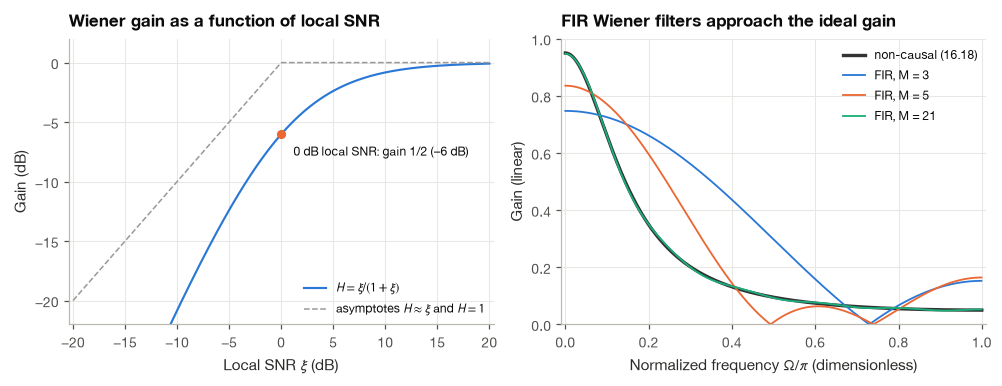

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
xi_db = np.linspace(-20, 20, 400)
xi = 10 ** (xi_db / 10)
ax = axes[0]
ax.plot(xi_db, 20 * np.log10(xi / (1 + xi)), color=C[0], label=r"$H = \xi / (1 + \xi)$")
ax.plot(xi_db, np.minimum(xi_db, 0), "--", color="0.6", lw=1, label=r"asymptotes $H \approx \xi$ and $H = 1$")
ax.plot(0, 20 * np.log10(0.5), "o", color=C[1])
ax.annotate("0 dB local SNR: gain 1/2 (−6 dB)", (0, -6.02), textcoords="offset points",
            xytext=(8, -14), fontsize=8)
ax.set(xlabel=r"Local SNR $\xi$ (dB)", ylabel="Gain (dB)", ylim=(-22, 2),
       title="Wiener gain as a function of local SNR")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
pos = Om >= 0
ax.plot(Om[pos] / np.pi, H_ideal[pos], color="0.2", lw=2.2, label="non-causal (16.18)")
for c, M in zip(C[:3], (3, 5, 21)):
    w, _ = wiener_ar1(M, (M - 1) // 2)
    wf, Hm = signal.freqz(w, worN=1024)
    ax.plot(wf / np.pi, np.abs(Hm), color=c, lw=1.2, label=f"FIR, M = {M}")
ax.set(xlabel=r"Normalized frequency $\Omega/\pi$ (dimensionless)", ylabel="Gain (linear)", ylim=(0, 1.0),
       title="FIR Wiener filters approach the ideal gain")
ax.legend(loc="upper right", fontsize=8)
plt.show()

(sec-10-2-4)=
## 10.2.4 Muscle Noise on the ECG

We now turn to real data and work through the problem step by step.

### Step 1: Build the test signal

The clean signal is the five-minute reference of [Section 12.1](../ch18_ecg_preprocessing/01_ecg_noise_types.ipynb): minutes 12 to 17 of the MLII lead of MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`. The noise is channel `noise1` of the `ma` (muscle artifact) record of the Noise Stress Test Database {cite:p}`moody1984,goldberger2000`, taken from the same five minutes. Two preparatory choices keep the experiment focused on muscle noise:

- The `ma` record is not pure EMG. As the band-power table of [Section 12.1](../ch18_ecg_preprocessing/01_ecg_noise_types.ipynb) shows, about 80 % of its power is slow drift below 0.5 Hz. Baseline wander has its own methods ([Section 12.2](../ch18_ecg_preprocessing/02_highpass_baseline_wander.ipynb)), so we remove it from the noise record with a zero-phase 1 Hz high-pass before adding the noise.
- For the same reason I take as the clean reference the ECG after a zero-phase 0.5 Hz high-pass. Without this step, the small baseline drift that record 100 already contains would count as signal, and a filter that removed it would be penalized.

We scale the noise to an input SNR of 0 dB with the gain of equation (12.6) in [Section 12.1](../ch18_ecg_preprocessing/01_ecg_noise_types.ipynb): $P_s$ is the power of the mean-removed clean ECG, $P_v$ the power of the noise, and the noise is multiplied by $\sqrt{P_s/(P_v\,10^{\mathrm{SNR}/10})}$. A 0 dB muscle artifact is severe but not unusual: during vigorous exercise or shivering, the muscle hash on a chest lead can have the same RMS value as the ECG, whose power is concentrated in the brief QRS complexes.

In [7]:
fs = 360
seg_from, seg_to = 12 * 60 * fs, 17 * 60 * fs          # minutes 12 to 17, as in Section 18.1
ecg_raw = wfdb.rdrecord("../data/mitdb/100", sampfrom=seg_from, sampto=seg_to, channels=[0]).p_signal[:, 0]
ma_raw = wfdb.rdrecord("../data/nstdb/ma", sampfrom=seg_from, sampto=seg_to, channels=[0]).p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=seg_from, sampto=seg_to)
r_peaks = ann.sample[np.isin(ann.symbol, ["N", "A", "V", "F", "S", "Q"])] - seg_from

s = signal.sosfiltfilt(signal.butter(2, 0.5, "high", fs=fs, output="sos"), ecg_raw)
v_unit = signal.sosfiltfilt(signal.butter(2, 1.0, "high", fs=fs, output="sos"), ma_raw)
t = np.arange(len(s)) / fs


def scaled_noise(s, v, snr_db):
    """Return v scaled by the gain of equation (18.6), so that 10 log10(P_s / P_v) = snr_db."""
    P_s = np.mean((s - s.mean()) ** 2)
    return v * np.sqrt(P_s / (np.mean(v**2) * 10 ** (snr_db / 10)))


v = scaled_noise(s, v_unit, 0.0)
x = s + v
P_s = np.mean((s - s.mean()) ** 2)
print(f"Beats in the segment          : {len(r_peaks)}")
print(f"RMS of clean ECG / noise      : {np.sqrt(P_s):.3f} mV / {np.sqrt(np.mean(v**2)):.3f} mV")
print(f"Input SNR check               : {10 * np.log10(P_s / np.mean(v**2)):.2f} dB")

Beats in the segment          : 375
RMS of clean ECG / noise      : 0.189 mV / 0.189 mV
Input SNR check               : 0.00 dB


### Step 2: Compare the spectra of signal and noise

Before designing anything, we compare the spectra. Welch's method ([Section 7.3](../ch12_spectral_estimation/03_nonparametric_psd.ipynb)) with 1024-sample (2.8 s) segments gives smooth estimates of $S_s$ and $S_v$, and their ratio is the local SNR $\xi(f)$ that, by [(10.19)](#eq-10-19), fully determines the optimal filter. Because this calculation uses the true clean signal and the true added noise, I call the resulting filter the **oracle** Wiener filter. No real application has these spectra, but the oracle is the benchmark for everything that follows.

In [8]:
nper = 1024
f_w, S_s_hat = signal.welch(s, fs, nperseg=nper)
_, S_v_hat = signal.welch(v, fs, nperseg=nper)
xi_hat = S_s_hat / S_v_hat
H_oracle = xi_hat / (1 + xi_hat)                      # equation (16.19)

cross = f_w[np.argmax((xi_hat < 1) & (f_w > 5))]
print("Local SNR at 10 / 20 / 40 Hz : "
      + " / ".join(f"{10 * np.log10(np.interp(fq, f_w, xi_hat)):+.1f} dB" for fq in (10, 20, 40)))
print(f"Local SNR first falls below 0 dB above 5 Hz at {cross:.1f} Hz")

Local SNR at 10 / 20 / 40 Hz : +8.0 dB / +1.4 dB / -8.4 dB
Local SNR first falls below 0 dB above 5 Hz at 19.3 Hz


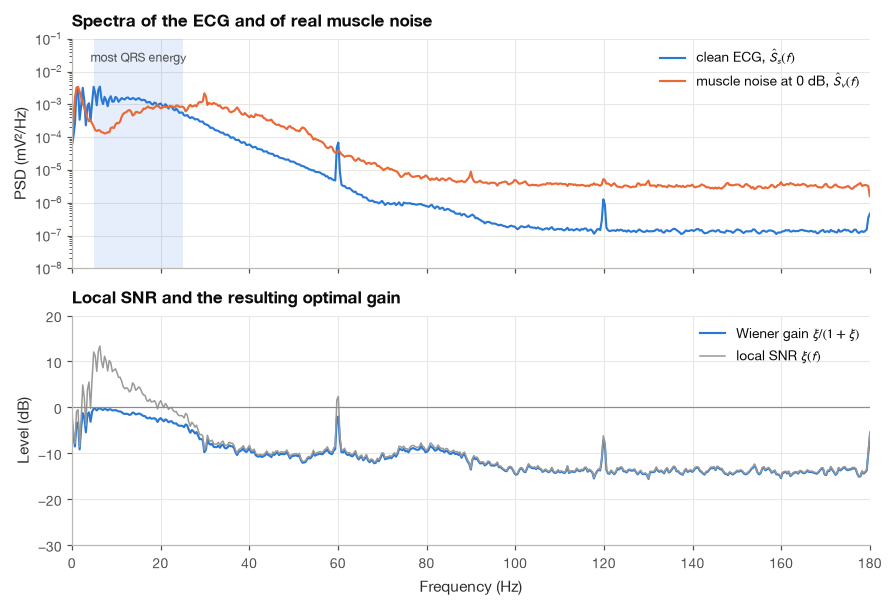

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True)
ax = axes[0]
ax.semilogy(f_w, S_s_hat, color=C[0], label=r"clean ECG, $\hat{S}_s(f)$")
ax.semilogy(f_w, S_v_hat, color=C[1], label=r"muscle noise at 0 dB, $\hat{S}_v(f)$")
ax.axvspan(5, 25, color=C[0], alpha=0.12, lw=0)
ax.text(15, 2e-2, "most QRS energy", ha="center", fontsize=8, color="0.3")
ax.set(ylabel="PSD (mV²/Hz)", ylim=(1e-8, 1e-1), title="Spectra of the ECG and of real muscle noise")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(f_w, 10 * np.log10(H_oracle), color=C[0], label=r"Wiener gain $\xi/(1+\xi)$")
ax.plot(f_w, 10 * np.log10(xi_hat), color="0.6", lw=1, label=r"local SNR $\xi(f)$")
ax.axhline(0, color="0.55", lw=0.8)
ax.set(xlabel="Frequency (Hz)", ylabel="Level (dB)", xlim=(0, 180), ylim=(-30, 20),
       title="Local SNR and the resulting optimal gain")
ax.legend(loc="upper right")
plt.show()

The picture explains the whole problem. The ECG spectrum is highest between about 5 and 25 Hz, where the QRS lives, and falls by three to four decades towards 100 Hz. The muscle noise spectrum is much flatter, so the local SNR is positive at low frequencies, crosses 0 dB near the upper edge of the QRS band, and is strongly negative above 40 Hz. The noise is far from negligible inside the QRS band itself. The local SNR is +8.0 dB at 10 Hz, only +1.4 dB at 20 Hz and −8.4 dB at 40 Hz, so the optimal gain stays within 1 dB of unity at 10 Hz, is about 2 dB down at 20 Hz and about 9 dB down at 40 Hz. This is the overlap that [(10.20)](#eq-10-20) warns about. One detail reminds us that the reference is not perfect: record 100 contains a weak 60 Hz line (noted in [Section 12.1](../ch18_ecg_preprocessing/01_ecg_noise_types.ipynb)), which the oracle treats as signal, so its gain jumps up at exactly 60 Hz.

(sec-10-2-5)=
## 10.2.5 An FIR Wiener Filter Trained with a Known Clean Signal

Suppose that, for one stretch of the recording, we know both the noisy signal and the clean one. This happens in a noise stress test, where noise is added to a clean recording on purpose, and in some laboratory settings where the noise source can be recorded separately. We can then estimate $R_x[k]$ and $p_k = \mathbb{E}\big[s[n-D]\,x[n-k]\big]$ from the training data, solve [(10.13)](#eq-10-13) once, and apply the resulting FIR filter to new data.

### Step 3: Train the FIR filter and check orthogonality

We train on the first 60 s and test on the remaining 240 s. I chose $M = 61$ taps (170 ms) and a delay of $D = 30$ samples (83 ms), so the filter estimates each sample from 83 ms of past and 83 ms of future input, a window a little wider than a QRS complex. Two implementations of the solve are compared: a general linear solver applied to the full Toeplitz matrix, and the Levinson recursion in `scipy.linalg.solve_toeplitz`, which exploits the Toeplitz structure and needs $O(M^2)$ instead of $O(M^3)$ operations.

In [10]:
def fir_wiener_stats(x_train, s_train, M, D):
    """Estimate R_x[k] and p_k = E[s[n-D] x[n-k]] (k = 0..M-1) from training data, eq. (16.13)."""
    xm, sm = x_train - x_train.mean(), s_train - s_train.mean()
    N = len(xm)
    r = corr_est(xm, xm, M)
    p_vec = np.array([np.dot(sm[np.arange(max(D, k), N) - D], xm[np.arange(max(D, k), N) - k]) / N
                      for k in range(M)])
    return r, p_vec


def apply_fir(x, w, D):
    """Filter x with w and remove the D-sample delay so the output lines up with x."""
    return np.convolve(x, w)[D:D + len(x)]


train = slice(0, 60 * fs)
test = slice(60 * fs, None)
M, D = 61, 30
r_tr, p_tr = fir_wiener_stats(x[train], s[train], M, D)
w_full = np.linalg.solve(linalg.toeplitz(r_tr), p_tr)
w_lev = linalg.solve_toeplitz(r_tr, p_tr)
print(f"Max |difference| between solvers : {np.max(np.abs(w_full - w_lev)):.2e}")

s_fir = apply_fir(x, w_lev, D)
e_train = (s - s_fir)[train]
orth = corr_est(e_train - e_train.mean(), x[train] - x[train].mean(), M) / np.var(x[train])
print(f"Max normalized E[e x[n-k]] on the training data: {np.max(np.abs(orth)):.4f}")
print(f"Sum of the taps (DC gain)                      : {w_lev.sum():.3f}")

Max |difference| between solvers : 1.40e-14
Max normalized E[e x[n-k]] on the training data: 0.0228
Sum of the taps (DC gain)                      : 0.452


The two solvers agree to rounding error, and the normalized correlation between the training error and every input sample is at most about 0.02, as [(10.12)](#eq-10-12) requires (the small residual comes from the boundaries of the finite sums and from the mean removal). The taps, plotted later in [Section 10.2.7](#sec-10-2-7), form a symmetric smoothing kernel about 50 ms wide. Their sum, the gain at 0 Hz, is only 0.45, but this does not matter: after the high-pass filters of Step 1 neither the signal nor the noise has anything left near 0 Hz, so the data give the filter no reason to care about that frequency. We score the filter on the test data with the quality metrics of [Section 12.1](../ch18_ecg_preprocessing/01_ecg_noise_types.ipynb): the SNR improvement $\Delta\mathrm{SNR}$, the RMSE, the PRD and the correlation coefficient $\rho$.

In [11]:
def quality(s_hat, s, x):
    """Delta SNR, RMSE, PRD and correlation, as defined in Section 18.1."""
    err = s_hat - s
    P_sig = np.mean((s - s.mean()) ** 2)
    snr_in = 10 * np.log10(P_sig / np.mean((x - s) ** 2))
    snr_out = 10 * np.log10(P_sig / np.mean(err**2))
    return {"ΔSNR (dB)": snr_out - snr_in,
            "RMSE (mV)": np.sqrt(np.mean(err**2)),
            "PRD (%)": 100 * np.sqrt(np.sum(err**2) / np.sum((s - s.mean()) ** 2)),
            "ρ": np.corrcoef(s_hat, s)[0, 1]}


q = quality(s_fir[test], s[test], x[test])
print("FIR Wiener on the test data: " + ", ".join(f"{k} = {val:.3f}" for k, val in q.items()))

FIR Wiener on the test data: ΔSNR (dB) = 4.477, RMSE (mV) = 0.115, PRD (%) = 60.527, ρ = 0.797


(sec-10-2-6)=
## 10.2.6 A Wiener Filter Estimated from the Recording Itself

In most clinical recordings there is no clean version to train on. Equation [(10.18)](#eq-10-18) shows that we do not really need one: it is enough to estimate the two power spectra. The noise spectrum alone is often available from a stretch of recording without signal, but the ECG never stops. For a repetitive signal we can borrow the idea of [Section 10.1](01_signal_averaging.ipynb) instead. Averaging hundreds of beats aligned on their R peaks cancels the uncorrelated noise and leaves a clean beat template. Placing that template at every R peak produces a *template train*, a noise-free approximation of the ECG, and the difference between the recording and the template train approximates the noise. Their Welch spectra are our estimates $\hat{S}_s$ and $\hat{S}_v$.

### Step 4: Estimate both spectra from averaged beats

The method needs the R-peak locations. We take them from the database annotations; in practice a QRS detector such as the Pan–Tompkins algorithm of Section 19.1 provides them, and QRS detection tolerates much more noise than waveform analysis does. Each beat window runs from 250 ms before to 450 ms after the R peak. Since this filter is applied offline, we apply [(10.18)](#eq-10-18) directly in the frequency domain: we take the FFT of the whole record, multiply each bin by the gain interpolated from the Welch grid, and transform back. A real, non-negative gain has zero phase, so nothing is shifted in time.

In [12]:
pre, post = int(0.25 * fs), int(0.45 * fs)


def template_train(x, peaks, pre, post):
    """Average the beats of x around the given R peaks and place the average at every peak."""
    peaks = peaks[(peaks - pre >= 0) & (peaks + post < len(x))]
    template = np.mean([x[k - pre:k + post] for k in peaks], axis=0)
    y = np.zeros_like(x)
    hits = np.zeros_like(x)
    for k in peaks:
        y[k - pre:k + post] += template
        hits[k - pre:k + post] += 1
    y[hits > 0] /= hits[hits > 0]                  # average where windows overlap
    y[hits == 0] = np.median(template[:20])        # isoelectric level between beats
    return y, template


def wiener_fft(x, f_grid, gain):
    """Apply a real, zero-phase gain defined on f_grid to x through one long FFT."""
    X = np.fft.rfft(x - x.mean())
    fk = np.fft.rfftfreq(len(x), 1 / fs)
    return np.fft.irfft(X * np.interp(fk, f_grid, gain), len(x)) + x.mean()


s_tpl, template = template_train(x, r_peaks, pre, post)
_, S_s_data = signal.welch(s_tpl - s_tpl.mean(), fs, nperseg=nper)
_, S_v_data = signal.welch(x - s_tpl, fs, nperseg=nper)
H_data = S_s_data / (S_s_data + S_v_data)

_, template_clean = template_train(s, r_peaks, pre, post)
print(f"Template RMS difference from the clean-signal template: "
      f"{1000 * np.sqrt(np.mean((template - template_clean) ** 2)):.1f} uV")

s_data = wiener_fft(x, f_w, H_data)
s_orac = wiener_fft(x, f_w, H_oracle)
for name, est in [("Wiener from data", s_data), ("oracle Wiener", s_orac)]:
    q = quality(est[test], s[test], x[test])
    print(f"{name:17s}: " + ", ".join(f"{k} = {val:.3f}" for k, val in q.items()))

Template RMS difference from the clean-signal template: 8.9 uV
Wiener from data : ΔSNR (dB) = 4.774, RMSE (mV) = 0.111, PRD (%) = 58.491, ρ = 0.811
oracle Wiener    : ΔSNR (dB) = 4.784, RMSE (mV) = 0.111, PRD (%) = 58.424, ρ = 0.812


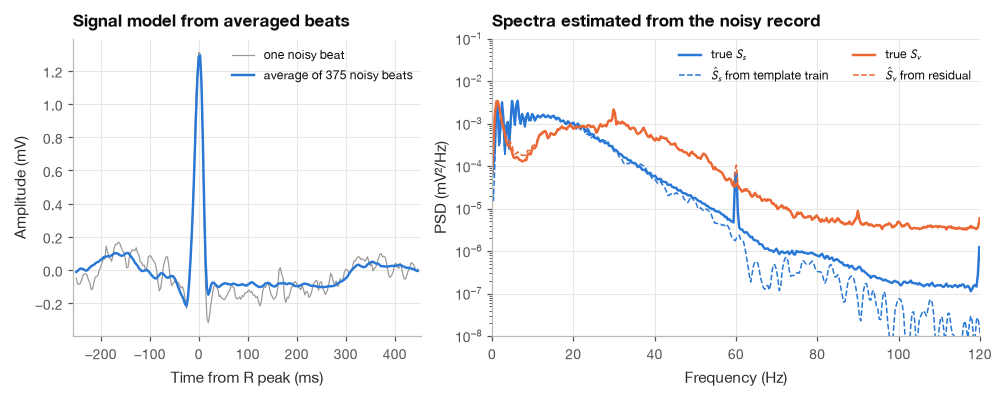

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
tb = (np.arange(-pre, post) / fs) * 1000
ax.plot(tb, x[r_peaks[10] - pre:r_peaks[10] + post], color="0.6", lw=0.8, label="one noisy beat")
ax.plot(tb, template, color=C[0], lw=1.6, label=f"average of {len(r_peaks)} noisy beats")
ax.set(xlabel="Time from R peak (ms)", ylabel="Amplitude (mV)", title="Signal model from averaged beats")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
ax.semilogy(f_w, S_s_hat, color=C[0], lw=1.6, label=r"true $S_s$")
ax.semilogy(f_w, S_s_data, color=C[0], lw=1.0, ls="--", label=r"$\hat{S}_s$ from template train")
ax.semilogy(f_w, S_v_hat, color=C[1], lw=1.6, label=r"true $S_v$")
ax.semilogy(f_w, S_v_data, color=C[1], lw=1.0, ls="--", label=r"$\hat{S}_v$ from residual")
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz)", xlim=(0, 120), ylim=(1e-8, 1e-1),
       title="Spectra estimated from the noisy record")
ax.legend(loc="upper right", fontsize=8, ncols=2)
plt.show()

The average of the noisy beats is almost indistinguishable from the average of the clean ones, and the two estimated spectra follow the true ones closely across the band that matters. The template train has no beat-to-beat variability, so it underestimates the signal spectrum, most visibly above about 40 Hz where the fine details of individual beats live, and that variability is counted as noise instead. Where it matters for the gain, below about 40 Hz, the estimates are close. The filter estimated from the noisy recording alone ends up within a small fraction of a decibel of the oracle. Record 100 is an easy case for this trick, with hundreds of beats of nearly identical shape in five minutes, but the idea carries over to any recording with a stable dominant morphology.

(sec-10-2-7)=
## 10.2.7 Comparison with a Fixed Low-Pass Filter

How do these filters compare with the fixed low-pass filters that a monitor would use? Section 18.3 studies the choice of a low-pass cutoff for muscle noise in detail; here we need only two representatives.

### Step 5: Score every filter on the test data

We take two fourth-order Butterworth low-pass filters applied forward and backward (Section 15.3): one at 40 Hz, the upper edge of the standard monitoring band, and one whose cutoff we choose by trying 10 to 75 Hz in 5 Hz steps and keeping the one with the lowest error on the test data. That second choice uses the clean signal and is therefore also a kind of oracle. I add one column that matters clinically: the average relative error in R-peak amplitude, measured at the annotated R peaks, since a filter that rounds the QRS lowers the R wave and can change the voltage criteria used, for example, to diagnose ventricular hypertrophy.

In [14]:
def lowpass(x, fc):
    """Zero-phase 4th-order Butterworth low-pass at fc Hz."""
    return signal.sosfiltfilt(signal.butter(4, fc, fs=fs, output="sos"), x)


def best_lowpass_cutoff(x, s, region):
    """Cutoff (10 to 75 Hz, 5 Hz steps) that minimizes the MSE on the given region."""
    errs = {fc: np.mean((lowpass(x, fc)[region] - s[region]) ** 2) for fc in range(10, 80, 5)}
    return min(errs, key=errs.get)


fc_best = best_lowpass_cutoff(x, s, test)
outputs = {"noisy input": x,
           "low-pass 40 Hz": lowpass(x, 40),
           f"low-pass {fc_best} Hz (best)": lowpass(x, fc_best),
           "FIR Wiener (trained)": s_fir,
           "Wiener from data": s_data,
           "oracle Wiener": s_orac}

r_test = r_peaks[r_peaks >= 60 * fs]
rows = []
for name, est in outputs.items():
    q = quality(est[test], s[test], x[test])
    q["R-amplitude error (%)"] = 100 * np.mean((est[r_test] - s[r_test]) / s[r_test])
    rows.append({"method": name, **q})
table = pd.DataFrame(rows).set_index("method")
print(table.to_string(float_format="%.3f"))

                       ΔSNR (dB)  RMSE (mV)  PRD (%)     ρ  R-amplitude error (%)
method                                                                           
noisy input                0.000      0.193  101.339 0.700                 -0.470
low-pass 40 Hz             1.080      0.171   89.488 0.735                 -3.391
low-pass 20 Hz (best)      3.148      0.134   70.529 0.757                -33.549
FIR Wiener (trained)       4.477      0.115   60.527 0.797                -38.217
Wiener from data           4.774      0.111   58.491 0.811                -41.353
oracle Wiener              4.784      0.111   58.424 0.812                -39.316


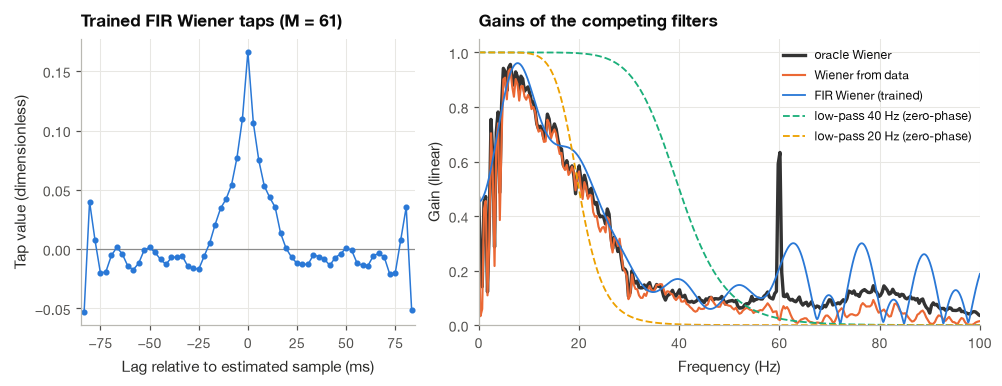

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
lags_ms = (np.arange(M) - D) / fs * 1000
ax.axhline(0, color="0.55", lw=0.8)
ax.plot(lags_ms, w_lev, "o-", color=C[0], ms=3, lw=1)
ax.set(xlabel="Lag relative to estimated sample (ms)", ylabel="Tap value (dimensionless)",
       title="Trained FIR Wiener taps (M = 61)")

ax = axes[1]
wf, H_fir = signal.freqz(w_lev, worN=4096, fs=fs)
_, H_lp40 = signal.sosfreqz(signal.butter(4, 40, fs=fs, output="sos"), worN=4096, fs=fs)
_, H_lpb = signal.sosfreqz(signal.butter(4, fc_best, fs=fs, output="sos"), worN=4096, fs=fs)
ax.plot(f_w, H_oracle, color="0.2", lw=2.2, label="oracle Wiener")
ax.plot(f_w, H_data, color=C[1], label="Wiener from data")
ax.plot(wf, np.abs(H_fir), color=C[0], lw=1.2, label="FIR Wiener (trained)")
ax.plot(wf, np.abs(H_lp40) ** 2, "--", color=C[2], lw=1.2, label="low-pass 40 Hz (zero-phase)")
ax.plot(wf, np.abs(H_lpb) ** 2, "--", color=C[3], lw=1.2, label=f"low-pass {fc_best} Hz (zero-phase)")
ax.set(xlabel="Frequency (Hz)", ylabel="Gain (linear)", xlim=(0, 100), ylim=(0, 1.05),
       title="Gains of the competing filters")
ax.legend(loc="upper right", fontsize=8)
plt.show()

By the MSE criterion the ranking is clear. The 40 Hz monitoring filter is almost useless against this noise: it improves the SNR by only 1.1 dB, because most of the muscle power that hurts lies below 40 Hz. The best low-pass, at 20 Hz, gains 3.1 dB. The Wiener filters gain 4.5 to 4.8 dB, and the filter estimated from the noisy record comes within 0.01 dB of the oracle. The gain plot shows why: the low-pass filters have a flat passband and a steep edge, so they pass the noise below their cutoff at full strength, while the Wiener gains taper gradually from about 0.9 near 7 Hz to about 0.1 at 35 Hz, following the local SNR.

The last column tells a less flattering story. The 40 Hz filter lowers the R peaks by about 3 %, the 20 Hz filter by about a third, and the Wiener filters by about 40 %. The MSE-optimal filter buys part of its error reduction by shrinking the QRS. The QRS occupies only about a tenth of each beat while the noise is present everywhere, so attenuating the 15 to 40 Hz band reduces the error in nine samples out of ten at the price of a large error in the remaining one. The MSE weighs every sample equally and judges this a good trade. A cardiologist measuring QRS voltages would not. The time traces below show what these numbers mean on two seconds of the test data.

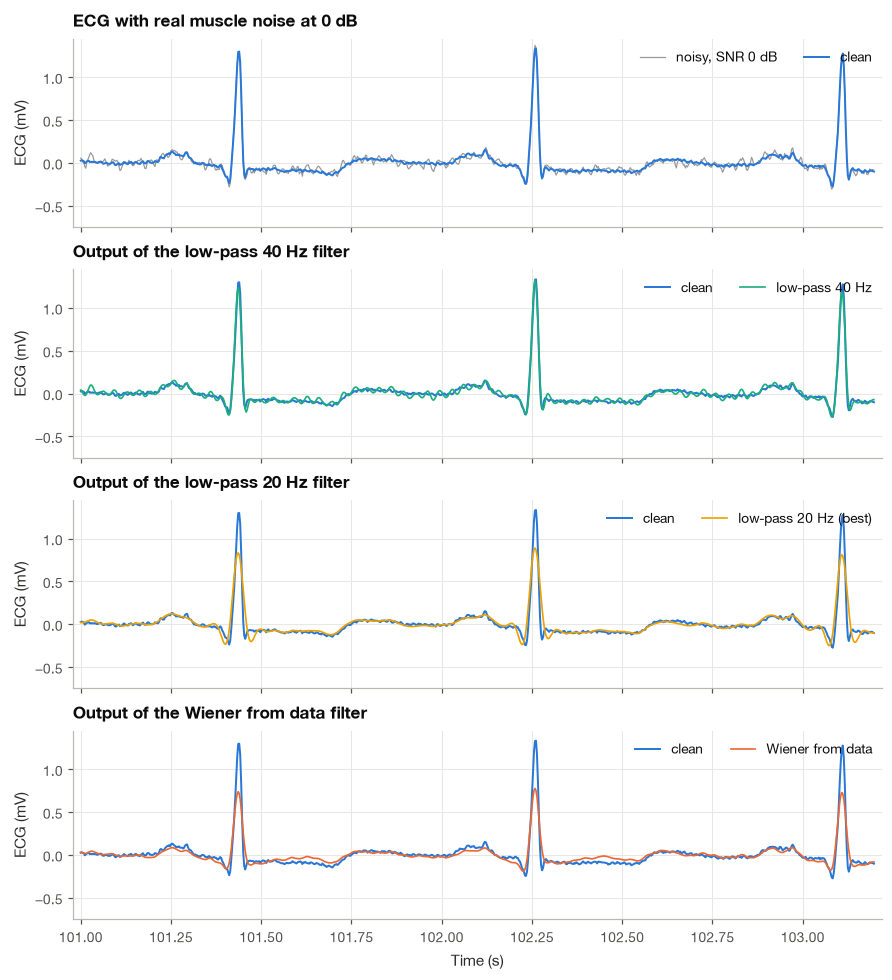

In [16]:
t0 = 101.0
win = (t >= t0) & (t < t0 + 2.2)
shown = [("low-pass 40 Hz", C[2]), (f"low-pass {fc_best} Hz (best)", C[3]), ("Wiener from data", C[1])]
fig, axes = plt.subplots(len(shown) + 1, 1, figsize=(8, 2.2 * (len(shown) + 1)), sharex=True)
axes[0].plot(t[win], x[win], color="0.6", lw=0.8, label="noisy, SNR 0 dB")
axes[0].plot(t[win], s[win], color=C[0], lw=1.3, label="clean")
axes[0].set(ylabel="ECG (mV)", title="ECG with real muscle noise at 0 dB")
axes[0].legend(loc="upper right", ncols=2)
for ax, (name, col) in zip(axes[1:], shown):
    ax.plot(t[win], s[win], color=C[0], lw=1.3, label="clean")
    ax.plot(t[win], outputs[name][win], color=col, lw=1.1, label=name)
    ax.set(ylabel="ECG (mV)", title=f"Output of the {name.replace(' (best)', '')} filter")
    ax.legend(loc="upper right", ncols=2)
axes[-1].set_xlabel("Time (s)")
for ax in axes:
    ax.set_ylim(-0.75, 1.45)
plt.show()

The 40 Hz output keeps the R peaks but still carries most of the noise. The 20 Hz output and the Wiener output both look much cleaner between the beats, where most of the samples are and where the Wiener output earns its lower MSE, and both pay for it at the R peaks, which drop from about 1.3 mV to roughly 0.85 mV and 0.75 mV. None of the outputs is both clean and faithful, and that is the honest conclusion: at 0 dB input SNR, even the best linear time-invariant filter gains only a few decibels against muscle noise, and it gains them partly at the expense of the QRS amplitude.

### Step 6: Repeat the comparison across noise levels

The optimal low-pass cutoff depends on the noise level, and so does the Wiener filter, which adjusts its gain through $\xi(f)$ automatically. The next cell repeats the comparison for input SNRs from 18 dB down to −6 dB. For each level it retrains the FIR Wiener filter, re-estimates the data-driven spectra and searches again for the best low-pass cutoff.

In [17]:
snr_levels = [18, 12, 6, 0, -6]
sweep = []
for snr in snr_levels:
    v_k = scaled_noise(s, v_unit, snr)
    x_k = s + v_k
    r_k, p_k = fir_wiener_stats(x_k[train], s[train], M, D)
    fir_k = apply_fir(x_k, linalg.solve_toeplitz(r_k, p_k), D)
    tpl_k, _ = template_train(x_k, r_peaks, pre, post)
    _, Ss_k = signal.welch(tpl_k - tpl_k.mean(), fs, nperseg=nper)
    _, Sv_k = signal.welch(x_k - tpl_k, fs, nperseg=nper)
    _, Sv_true = signal.welch(v_k, fs, nperseg=nper)
    fc_k = best_lowpass_cutoff(x_k, s, test)
    ests = {"low-pass 40 Hz": lowpass(x_k, 40), "best low-pass": lowpass(x_k, fc_k),
            "FIR Wiener (trained)": fir_k,
            "Wiener from data": wiener_fft(x_k, f_w, Ss_k / (Ss_k + Sv_k)),
            "oracle Wiener": wiener_fft(x_k, f_w, S_s_hat / (S_s_hat + Sv_true))}
    row = {"SNR in (dB)": snr, "best cutoff (Hz)": fc_k}
    row.update({name: quality(est[test], s[test], x_k[test])["ΔSNR (dB)"] for name, est in ests.items()})
    sweep.append(row)
sweep = pd.DataFrame(sweep).set_index("SNR in (dB)")
print("Improvement ΔSNR (dB) on the test data")
print(sweep.to_string(float_format="%.2f"))

Improvement ΔSNR (dB) on the test data
             best cutoff (Hz)  low-pass 40 Hz  best low-pass  FIR Wiener (trained)  Wiener from data  oracle Wiener
SNR in (dB)                                                                                                        
18                         75           -1.64          -0.08                  0.23             -0.97           0.28
12                         40            0.26           0.26                  0.79              0.61           0.92
6                          30            0.90           1.55                  2.09              2.30           2.35
0                          20            1.08           3.15                  4.48              4.77           4.78
-6                         10            1.13           4.98                  8.13              8.35           8.36


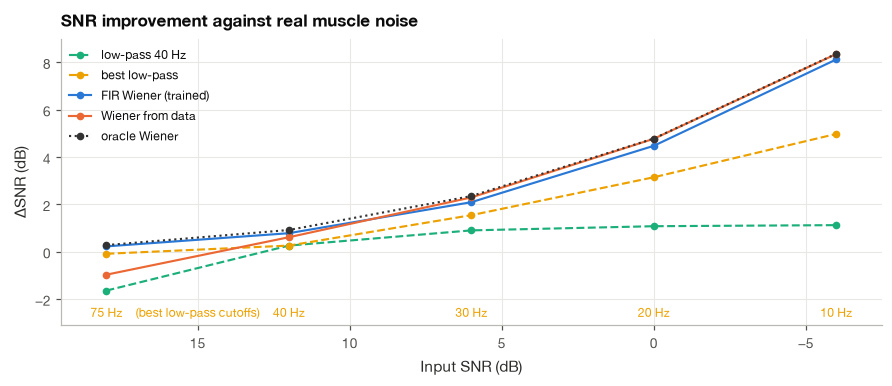

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.4))
styles = [("low-pass 40 Hz", C[2], "--"), ("best low-pass", C[3], "--"),
          ("FIR Wiener (trained)", C[0], "-"), ("Wiener from data", C[1], "-"),
          ("oracle Wiener", "0.2", ":")]
for name, col, ls in styles:
    ax.plot(sweep.index, sweep[name], ls, marker="o", color=col, ms=4, label=name)
for snr, fc in sweep["best cutoff (Hz)"].items():
    ax.text(snr, -2.75, f"{fc:.0f} Hz", ha="center", fontsize=8, color=C[3])
ax.text(15, -2.75, "(best low-pass cutoffs)", ha="center", fontsize=8, color=C[3])
ax.set(xlabel="Input SNR (dB)", ylabel="ΔSNR (dB)", xlim=(19.5, -7.5), ylim=(-3.1, 9),
       title="SNR improvement against real muscle noise")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Read the plot from left to right, from mild to severe noise (the axis is reversed). At 18 dB there is almost nothing to gain. The trained FIR and oracle Wiener filters improve the SNR by about 0.25 dB, the best low-pass sits at the top of our search range (75 Hz) and still loses 0.08 dB, and the 40 Hz filter loses 1.6 dB because the QRS distortion it causes is larger than the little noise it removes. The data-driven Wiener filter loses about 1 dB at this level, for a reason we can name: the template train has no beat-to-beat variability, so the real variability of the ECG is counted as noise in $\hat{S}_v$. At 0 dB that error is negligible next to the added noise; at 18 dB it is not, and the filter becomes too aggressive.

As the noise grows, every method gains more, because there is more noise to remove, and the Wiener filters pull clearly ahead: at −6 dB they gain more than 8 dB, against 5.0 dB for the best low-pass. The best low-pass cutoff (printed along the bottom of the plot) falls from 75 Hz in mild noise to 10 Hz in severe noise. A designer who wants the best fixed low-pass has to know the SNR in advance, which is exactly the information the Wiener filter encodes in its gain. The 40 Hz filter, chosen without regard to the noise, never gains more than about 1.1 dB.

(sec-10-2-8)=
## 10.2.8 Limitations of the Wiener Filter

The Wiener filter is optimal, but only within the assumptions that produced it, and each of them is strained by real biomedical noise.

**Stationarity.** The derivation assumes that the spectra do not change over time, so a single gain serves the whole record. Muscle noise is anything but stationary: it comes in bursts that follow the patient's movements. The next cell measures the noise RMS in consecutive 10 s windows of the test data.

In [19]:
win_rms = np.array([np.sqrt(np.mean(v[k:k + 10 * fs] ** 2)) for k in range(60 * fs, len(v), 10 * fs)])
print(f"Noise RMS in 10 s windows: min {win_rms.min():.3f} mV, median {np.median(win_rms):.3f} mV, "
      f"max {win_rms.max():.3f} mV")
print(f"Ratio of loudest to quietest window: {win_rms.max() / win_rms.min():.1f} "
      f"({20 * np.log10(win_rms.max() / win_rms.min()):.1f} dB)")

Noise RMS in 10 s windows: min 0.033 mV, median 0.201 mV, max 0.277 mV
Ratio of loudest to quietest window: 8.4 (18.5 dB)


The quietest window has an RMS of 33 µV and the loudest 277 µV, a ratio of 8.4 or 18.5 dB. A local SNR that varies this much over the record means that the single average gain is too aggressive during quiet stretches, where it rounds the QRS for no benefit, and too timid during bursts. The standard remedy is a *short-time* Wiener filter that re-estimates $\hat{S}_v$ in sliding blocks, which is how many speech enhancement systems work; the alternative is to let the filter coefficients adapt sample by sample, the subject of Section 16.3.

**The statistics must be known.** The filter is only as good as its estimates of $R_x$ and $\mathbf{p}$, or of $S_s$ and $S_v$. We had the luxury of a known clean signal in one experiment and a highly repetitive ECG in the other. With irregular morphology (frequent ectopic beats, atrial fibrillation) the template train no longer represents the signal, and the spectral estimates degrade.

**Linearity and the MSE criterion.** A linear time-invariant filter can only weight frequencies. Equation [(10.20)](#eq-10-20) shows that when the spectra overlap, part of the error is irreducible for every such filter, and our experiment put a number on it: a few decibels at best against muscle noise on the ECG. Methods that exploit structure beyond the power spectrum, such as the sparsity of the ECG in a wavelet basis ([Section 14.2](../ch24_wavelets/02_wavelet_denoising.ipynb)) or the repetition of beats ([Section 10.1](01_signal_averaging.ipynb)), can beat the Wiener bound because they are not linear time-invariant filters. In addition, the MSE treats every sample alike. It does not know that a 0.1 mV error at the J point matters more clinically than the same error in the middle of the TP segment.

**Causality.** The frequency-domain filter [(10.18)](#eq-10-18) is non-causal. A causal infinite-length Wiener filter exists, but deriving it requires the spectral factorization of $S_x$ and is beyond our scope {cite:p}`haykin2014`. In practice a delayed FIR solution such as our 61-tap filter, with a latency of 83 ms, is an acceptable compromise for monitoring.

```{note}
I find the data-driven Wiener filter most useful as a yardstick rather than as a production denoiser. If a new nonlinear ECG denoising method cannot beat the Wiener filter estimated from averaged beats on a noise stress test, it is not yet worth its extra complexity, and if it beats it only in MSE while shrinking the QRS further, it has not really won.
```

## Summary

The Wiener filter is the linear filter that minimizes the mean squared error between its output and a desired signal. Requiring the error to be orthogonal to every input sample leads to the Wiener–Hopf equations $\mathbf{R}\mathbf{w}_o = \mathbf{p}$, a Toeplitz linear system built from the input autocorrelation and the cross-correlation between input and target, and the error surface is a quadratic bowl with its minimum at $\mathbf{w}_o$. Removing the restrictions on filter length and causality gives the frequency-domain form $H = S_s/(S_s + S_v) = \xi/(1 + \xi)$: a real gain between 0 and 1 set at each frequency by the local SNR, with a minimum error that comes only from the frequencies where signal and noise overlap.

On ECG corrupted by real muscle noise, an FIR Wiener filter trained on a clean segment and a frequency-domain filter estimated from the noisy recording alone, using an averaged-beat template for the signal spectrum, both outperformed every fixed low-pass filter in MSE and approached the oracle bound, yet gained only a few decibels, because muscle noise and the QRS complex share the same band. Part of that gain came from shrinking the R peaks, a reminder that the MSE is not a clinical criterion. The Wiener filter also assumes fixed statistics that we know in advance. Adaptive filters drop both assumptions: they start from no knowledge, learn the solution of the Wiener–Hopf equations from the data as it arrives, and keep following it as the statistics change. Section 16.3 derives the LMS and RLS algorithms as iterative ways of descending the same error bowl we drew in [Section 10.2.2](#sec-10-2-2).

## Exercises

1. **A scalar Wiener filter.** Let $s[n]$ be white with variance $\sigma_s^2$ and $v[n]$ white with variance $\sigma_v^2$, uncorrelated with $s$. Show that the Wiener filter of any length reduces to a single gain $\sigma_s^2/(\sigma_s^2 + \sigma_v^2)$, and compute $J_{\min}$. Explain in words why longer filters do not help here.
2. **A hidden identity.** In Example 10.2.1, $J_{\min}$ came out equal to $w_0$. Using the first row of $\mathbf{R}\mathbf{w}_o = \mathbf{p}$ and [(10.14)](#eq-10-14), prove that $J_{\min} = \sigma_v^2\,w_0$ holds for any signal in white noise when $D = 0$. Check the identity numerically for $M = 5$.
3. **Smoothing by hand.** Repeat Example 10.2.1 with $M = 3$ and delay $D = 1$. Write down $\mathbf{R}$ and $\mathbf{p}$, solve the system (by hand or with a computer algebra system), and confirm the MSE given in the table of [Section 10.2.3](#sec-10-2-3).
4. **Correlated signal and noise.** Derive the non-causal Wiener filter when $s$ and $v$ are correlated, with cross-spectrum $S_{sv}(\Omega)$. Show that $H = (S_s + S_{sv})/(S_s + S_v + 2\operatorname{Re}\{S_{sv}\})$, with the cross-spectrum defined so that $S_{sx} = S_s + S_{sv}$.
5. **Electrode motion.** Repeat the comparison of [Section 10.2.7](#sec-10-2-7) using the `em` record of the Noise Stress Test Database instead of `ma`. Plot the local SNR $\xi(f)$ and explain, using [(10.20)](#eq-10-20), why the improvement achievable by any linear filter is smaller.
6. **A short-time Wiener filter.** Implement a block-wise Wiener filter that keeps the signal spectrum from the template train but re-estimates the noise spectrum from the residual $x - (\text{template train})$ in 10 s blocks with 50 % overlap, applies the gain to each block in the frequency domain, and recombines the blocks by overlap-add with a Hann window. Compare its ΔSNR and R-amplitude error with the stationary filter at 0 dB, and discuss the role of the block length.

## Further Reading

The original theory, developed for anti-aircraft fire control and circulated during the war as a classified report, was published as {cite:t}`wiener1949`. {cite:t}`haykin2014` (Chapter 2) derives the Wiener–Hopf equations, the error surface and the canonical form of the MSE in the notation of adaptive filtering, and it is the natural bridge to the next section. {cite:t}`papoulis2002` treats Wiener smoothing and prediction for random processes, including the causal solution by spectral factorization, and {cite:t}`sornmo2005` discuss linear and nonlinear noise reduction for the ECG, including the role of ensemble averaging in estimating signal statistics.